# Task 4: Supervised Learning Model Implementation

**Internship:** Virtual Data Science with Python

**Platform:** YuvaIntern

**Task:** Week 4 — Supervised Learning Model Implementation

**Project Title:** Retail Sales Prediction Using Supervised Learning

**Objective:** To design and implement a supervised machine learning model using Python to predict retail sales based on transaction-related features.

**Learning Type:** Supervised Learning

**Problem Type:** Regression

**Dataset:** Online Retail Dataset

**Libraries:** Pandas, NumPy, Matplotlib, Seaborn, and Scikit-learn

**Key Techniques:** Data Preprocessing, Feature Engineering, Train-Test Split, Model Training, Cross-Validation, and Model Evaluation

## 1. Import Required Libraries

In this section, we import the Python libraries required for data manipulation, data visualization, feature preprocessing, supervised learning, cross-validation, and model evaluation.

The Scikit-learn library will be used to build and evaluate the regression model.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")


All libraries imported successfully!


## 2. Load the Dataset

In this section, we load the cleaned Online Retail dataset used in the previous task.

The dataset contains retail transaction information. We will inspect its structure, column names, data types, and sample records before preparing it for supervised learning.

In [2]:

df = pd.read_csv("online_retail_cleaned.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nFirst Five Rows:")
display(df.head())


Dataset loaded successfully!
Dataset Shape: (536641, 8)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 536641 entries, 0 to 536640
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    536641 non-null  object 
 1   StockCode    536641 non-null  object 
 2   Description  535187 non-null  object 
 3   Quantity     536641 non-null  int64  
 4   InvoiceDate  536641 non-null  object 
 5   UnitPrice    536641 non-null  float64
 6   CustomerID   401604 non-null  float64
 7   Country      536641 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 32.8+ MB

First Five Rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom


## 3. Data Preparation and Feature Selection

In this section, we inspect the dataset for missing values and duplicate records and prepare the data for supervised learning.

The target variable will be `TotalSales`, representing the total value of a transaction. The features will be selected carefully to avoid using variables that directly calculate the target, reducing the risk of data leakage.

In [3]:

# Create a working copy of the dataset
data = df.copy()

# Display missing values in each column
print("Missing Values:")
display(data.isnull().sum())

# Check duplicate records
print("\nDuplicate Rows:", data.duplicated().sum())

# Display available columns
print("\nAvailable Columns:")
print(data.columns.tolist())

# Display basic statistics
print("\nDataset Summary:")
display(data.describe(include="all").T)


Missing Values:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64


Duplicate Rows: 0

Available Columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
InvoiceNo,536641,25900,573585,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,536641,4070,85123A,2301,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,535187,4223,WHITE HANGING HEART T-LIGHT HOLDER,2357,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,536641.0,NaN,NaN,NaN,9.620029,219.130156,-80995.0,1.0,3.0,10.0,80995.0
InvoiceDate,536641,23260,31-10-2011 14:41,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UnitPrice,536641.0,NaN,NaN,NaN,4.632656,97.233118,-11062.06,1.25,2.08,4.13,38970.0
CustomerID,401604.0,NaN,NaN,NaN,15281.160818,1714.006089,12346.0,13939.0,15145.0,16784.0,18287.0
Country,536641,38,United Kingdom,490300,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Data Cleaning and Target Variable Creation

In this section, we prepare the retail transaction data for regression analysis.

We remove records with missing values in the required columns, exclude invalid transactions with non-positive quantities or unit prices, and create the target variable `TotalSales` when it is not already available.

The target variable represents the total sales value of each transaction. The input features will be selected separately to avoid direct target leakage.

In [6]:

# Make a copy of the dataset
data = df.copy()

# Convert InvoiceDate to datetime if available
if "InvoiceDate" in data.columns:
    data["InvoiceDate"] = pd.to_datetime(
        data["InvoiceDate"], errors="coerce"
    )

# Remove cancelled invoices if InvoiceNo exists
if "InvoiceNo" in data.columns:
    data = data[
        ~data["InvoiceNo"].astype(str).str.startswith("C")
    ]

# Remove invalid quantities and prices
if "Quantity" in data.columns and "UnitPrice" in data.columns:
    data = data[
        (data["Quantity"] > 0) &
        (data["UnitPrice"] > 0)
    ]

# Create the target if it does not already exist
if "TotalSales" not in data.columns:
    data["TotalSales"] = data["Quantity"] * data["UnitPrice"]

# Remove rows missing the target
data = data.dropna(subset=["TotalSales"])

print("Rows before cleaning:", len(df))
print("Rows after cleaning:", len(data))
print("Missing target values:", data["TotalSales"].isna().sum())

display(data.head())


Rows before cleaning: 536641
Rows after cleaning: 524878
Missing target values: 0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-01-12 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-01-12 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom,20.34


## 5. Feature Engineering

Feature engineering is the process of creating useful input variables from existing data.

In this project, transaction dates will be used to derive features such as month, day of the month, and day of the week. These features may help the regression model identify patterns in retail sales.

The target variable is `TotalSales`. Features that directly calculate the target, such as `Quantity` and `UnitPrice`, will not be used as predictors.

In [7]:

# Create a separate feature dataset
model_data = data.copy()

# Extract date-based features if InvoiceDate exists
if "InvoiceDate" in model_data.columns:
    model_data["InvoiceMonth"] = model_data["InvoiceDate"].dt.month
    model_data["InvoiceDay"] = model_data["InvoiceDate"].dt.day
    model_data["InvoiceWeekday"] = model_data["InvoiceDate"].dt.dayofweek

# Display available features
print("Available columns after feature engineering:")
print(model_data.columns.tolist())

display(model_data.head())


Available columns after feature engineering:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'TotalSales', 'InvoiceMonth', 'InvoiceDay', 'InvoiceWeekday']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales,InvoiceMonth,InvoiceDay,InvoiceWeekday
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-01-12 08:26:00,2.55,17850.0,United Kingdom,15.30,1.0,12.0,1.0
1,536365,71053,WHITE METAL LANTERN,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom,20.34,1.0,12.0,1.0
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-01-12 08:26:00,2.75,17850.0,United Kingdom,22.00,1.0,12.0,1.0
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom,20.34,1.0,12.0,1.0
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-01-12 08:26:00,3.39,17850.0,United Kingdom,20.34,1.0,12.0,1.0


## 6. Selection of Features and Target Variable

In supervised learning, input features are represented by `X`, while the target variable is represented by `y`.

In this project, `TotalSales` is the target variable. Date-derived features will be used as predictors when available. Identifiers and variables that directly determine the target will be excluded to reduce data leakage.

The selected features will be checked before model training.

In [8]:

# Select only features that were created from InvoiceDate
candidate_features = [
    "InvoiceMonth",
    "InvoiceDay",
    "InvoiceWeekday"
]

features = [
    col for col in candidate_features
    if col in model_data.columns
]

if not features:
    raise ValueError(
        "No date-based features found. Check whether InvoiceDate exists."
    )

X = model_data[features].copy()
y = model_data["TotalSales"].copy()

# Remove rows with missing values in selected features or target
valid_rows = X.notna().all(axis=1) & y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows]

print("Selected features:", features)
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())


Selected features: ['InvoiceMonth', 'InvoiceDay', 'InvoiceWeekday']
Feature matrix shape: (225423, 3)
Target shape: (225423,)


,InvoiceMonth,InvoiceDay,InvoiceWeekday
0,1.0,12.0,1.0
1,1.0,12.0,1.0
2,1.0,12.0,1.0
3,1.0,12.0,1.0
4,1.0,12.0,1.0


0    15.30
1    20.34
2    22.00
3    20.34
4    20.34
Name: TotalSales, dtype: float64

## 7. Train-Test Split and Model Training

The dataset is divided into training and testing subsets using an 80:20 ratio. The training data is used to fit the model, while the testing data is reserved for evaluating its performance on unseen records.

Linear Regression is selected as the baseline model because it is a simple and interpretable supervised learning algorithm for predicting continuous numerical values.

In [9]:

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

# Create and train the Linear Regression model
model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

print("\nLinear Regression model trained successfully!")


Training features shape: (180338, 3)
Testing features shape: (45085, 3)
Training target shape: (180338,)
Testing target shape: (45085,)

Linear Regression model trained successfully!


## 8. Model Evaluation

The trained Linear Regression model is evaluated using the test dataset, which was not used during model training.

The following evaluation metrics are used:

- **Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted sales.
- **Root Mean Squared Error (RMSE):** Measures prediction error while giving greater weight to larger errors.
- **R-squared (R²):** Measures how much variation in the target variable is explained by the model.

These metrics help assess the predictive performance and limitations of the regression model.

In [10]:

# Generate predictions on the test dataset
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("-" * 35)
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R2): {r2:.4f}")


Model Evaluation Results
-----------------------------------
Mean Absolute Error (MAE): 19.8474
Root Mean Squared Error (RMSE): 194.5735
R-squared (R2): -0.0001


### 8.1 Actual vs. Predicted Sales

This visualization compares the actual sales values with the values predicted by the trained model. Points closer to the diagonal line indicate more accurate predictions.

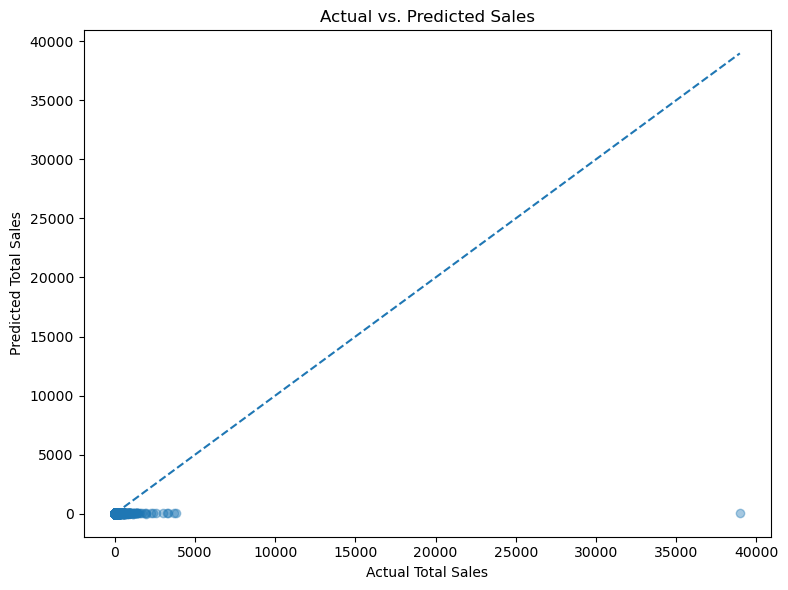

In [12]:

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.4)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Total Sales")
plt.ylabel("Predicted Total Sales")
plt.title("Actual vs. Predicted Sales")
plt.tight_layout()
plt.show()


## 9. Model Validation Using Cross-Validation

Cross-validation is used to evaluate the stability of a machine learning model across different subsets of the training data.

In this project, 5-fold cross-validation is performed using the training dataset. The negative Mean Absolute Error scoring method is used because Scikit-learn represents loss metrics as negative values during model selection. The scores are converted back to positive MAE values for interpretation.

In [13]:

# Perform 5-fold cross-validation on training data
cv_scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

# Convert negative MAE scores into positive values
cv_mae_scores = -cv_scores

print("Cross-Validation MAE Scores:", cv_mae_scores.round(4))
print("Mean Cross-Validation MAE:", round(cv_mae_scores.mean(), 4))
print("Standard Deviation:", round(cv_mae_scores.std(), 4))


Cross-Validation MAE Scores: [19.4945 23.5171 19.993  19.6579 20.184 ]
Mean Cross-Validation MAE: 20.5693
Standard Deviation: 1.4937


## 10. Model Coefficients and Performance Analysis

Linear Regression coefficients indicate how the model's predictions change with changes in the input features, while holding other features constant.

This analysis helps us understand how the date-based features contribute to the predicted transaction sales. The coefficients should be interpreted cautiously because relationships in historical data do not necessarily imply causation.

In [14]:

# Extract coefficients from the trained Linear Regression model
regressor = model.named_steps["regressor"]

coefficient_table = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": regressor.coef_
})

display(coefficient_table)

print("Intercept:", round(regressor.intercept_, 4))


,Feature,Coefficient
0,InvoiceMonth,0.722433
1,InvoiceDay,1.294057
2,InvoiceWeekday,-2.881207


Intercept: 20.8433


## 11. Conclusion

In this project, a supervised learning regression model was implemented using the cleaned Online Retail dataset.

Linear Regression was trained to predict transaction sales using date-derived features. The dataset was divided into training and testing subsets, and the model was evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-squared (R²).

Five-fold cross-validation was also performed on the training data to assess the consistency of the model's performance.

### Strengths
- Uses a simple and interpretable regression algorithm.
- Applies a separate test dataset for evaluation.
- Uses a pipeline to integrate feature scaling and model training.
- Uses cross-validation to assess performance stability.

### Limitations
- Date-based features alone may not capture the factors that determine transaction sales.
- Linear Regression may not represent complex relationships in retail data.
- Performance depends on the available features and quality of the dataset.
- Results from historical transactions may not generalize to future periods.

### Possible Improvements
- Engineer additional useful features without introducing target leakage.
- Compare Linear Regression with alternative regression models.
- Tune model parameters using appropriate validation methods.
- Investigate prediction errors and validate the model on relevant unseen data.

### Final Observation
The model's effectiveness should be assessed using the actual evaluation metrics produced by the notebook. The final report should include these measured results and discuss the model's limitations honestly.